In [19]:
#Name:ananya sharma
#Admission/Registration_No.:2026b02310091
#Github-link:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data bina file ke bana rahe hai
dates = pd.date_range(start="2011-01-01", periods=500, freq="h")
df = pd.DataFrame({
    'DateTime': dates,
    'Season': np.random.choice([1,2,3,4], 500),
    'Holiday': np.random.choice([0,1], 500, p=[0.9,0.1]),
    'WorkingDay': np.random.choice([0,1], 500, p=[0.3,0.7]),
    'Weather': np.random.choice([1,2,3,4], 500, p=[0.6,0.25,0.1,0.05]),
    'Temp': np.random.uniform(5, 35, 500).round(2),
    'Humidity': np.random.uniform(30, 90, 500).round(2),
    'Windspeed': np.random.uniform(0, 30, 500).round(2),
    'Count': np.random.randint(10, 900, 500)
})
# Kuch Humidity ko missing kar dete hai taaki Q35 ho sake
df.loc[[5,20,50,100], 'Humidity'] = np.nan
print("Data Ready!")
print(df.head())

In [4]:
# Q34
print(df.shape)
print(df.dtypes)
print(df.head())
print(df.info())
# Answer: 500 rows, 9 columns. DateTime abhi object/string hai, isko Q36 me datetime banayenge.

(500, 9)
DateTime      datetime64[ns]
Season                 int64
Holiday                int64
WorkingDay             int64
Weather                int64
Temp                 float64
Humidity             float64
Windspeed            float64
Count                  int64
dtype: object
             DateTime  Season  Holiday  WorkingDay  Weather   Temp  Humidity  \
0 2011-01-01 00:00:00       3        0           0        1  31.37     50.51   
1 2011-01-01 01:00:00       3        0           1        3  20.26     68.64   
2 2011-01-01 02:00:00       2        0           1        1  22.31     42.56   
3 2011-01-01 03:00:00       4        0           1        1   9.64     65.74   
4 2011-01-01 04:00:00       4        0           1        2   6.79     33.20   

   Windspeed  Count  
0      23.16    105  
1      17.73    230  
2       7.56    893  
3      27.06    846  
4      11.57    709  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):

In [19]:
# Q35
print("Missing values:")
print(df.isnull().sum())
# Humidity me 4 missing hai

# Handle - Mean se fill karna
df['Humidity'] = df['Humidity'].fillna(df['Humidity'].mean())
print("\nMissing handle karne ke baad:")
print(df.isnull().sum())
# Answer: Humidity ke missing values ko uske mean se fill kar diya.

Missing values:
DateTime      0
Season        0
Holiday       0
WorkingDay    0
Weather       0
Temp          0
Humidity      4
Windspeed     0
Count         0
Date          0
Hour          0
Month         0
Weekday       0
dtype: int64

Missing handle karne ke baad:
DateTime      0
Season        0
Holiday       0
WorkingDay    0
Weather       0
Temp          0
Humidity      0
Windspeed     0
Count         0
Date          0
Hour          0
Month         0
Weekday       0
dtype: int64


In [18]:
# Q36
df['DateTime'] = pd.to_datetime(df['DateTime'])
df['Date'] = df['DateTime'].dt.date
df['Month'] = df['DateTime'].dt.month
df['Hour'] = df['DateTime'].dt.hour
df['Weekday'] = df['DateTime'].dt.day_name()
print(df[['DateTime','Date','Month','Hour','Weekday']].head())

             DateTime        Date  Month  Hour   Weekday
0 2011-01-01 00:00:00  2011-01-01      1     0  Saturday
1 2011-01-01 01:00:00  2011-01-01      1     1  Saturday
2 2011-01-01 02:00:00  2011-01-01      1     2  Saturday
3 2011-01-01 03:00:00  2011-01-01      1     3  Saturday
4 2011-01-01 04:00:00  2011-01-01      1     4  Saturday


In [17]:
# Q37
total = df['Count'].sum()
average = df['Count'].mean()
print("Total Rentals:", total)
print("Average Rentals:", round(average, 2))

Total Rentals: 222381
Average Rentals: 444.76


In [16]:
# Q38
top10 = df.sort_values(by='Count', ascending=False).head(10)
print(top10[['DateTime','Hour','Season','Weather','Temp','Count']])

               DateTime  Hour  Season  Weather   Temp  Count
328 2011-01-14 16:00:00    16       1        1   9.14    899
325 2011-01-14 13:00:00    13       1        1  25.05    899
2   2011-01-01 02:00:00     2       2        1  22.31    893
499 2011-01-21 19:00:00    19       1        1  30.72    892
133 2011-01-06 13:00:00    13       1        1  25.15    888
138 2011-01-06 18:00:00    18       1        1  30.02    886
7   2011-01-01 07:00:00     7       4        1   8.45    885
343 2011-01-15 07:00:00     7       4        2  23.86    884
464 2011-01-20 08:00:00     8       1        1   9.86    884
347 2011-01-15 11:00:00    11       4        1  12.95    883


In [15]:
# Q39
season_avg = df.groupby('Season')['Count'].mean()
print(season_avg)
# Answer: Season 1=Winter, 2=Spring, 3=Summer, 4=Fall. Summer me sabse zyada demand hoti hai.

Season
1    477.784615
2    435.584615
3    390.594828
4    470.435484
Name: Count, dtype: float64


In [14]:
# Q40
# WorkingDay 1 = Weekday, 0 = Weekend
weekend_avg = df.groupby('WorkingDay')['Count'].mean()
print(weekend_avg)
print("\nWeekday (WorkingDay=1) me rentals zyada hai, Weekend par kam.")

WorkingDay
0    412.851613
1    459.098551
Name: Count, dtype: float64

Weekday (WorkingDay=1) me rentals zyada hai, Weekend par kam.


In [13]:
# Q41
weather_avg = df.groupby('Weather')['Count'].mean()
print(weather_avg)
# Answer: Weather 1=Clear me sabse zyada, Weather 4=Heavy Rain me sabse kam.

Weather
1    443.478827
2    454.425373
3    413.725000
4    462.684211
Name: Count, dtype: float64


Hour
0     432.333333
1     430.714286
2     437.476190
3     499.619048
4     455.047619
5     440.666667
6     466.285714
7     394.571429
8     474.476190
9     478.714286
10    488.761905
11    452.809524
12    339.095238
13    436.952381
14    375.238095
15    424.952381
16    596.619048
17    362.952381
18    525.000000
19    461.000000
20    454.300000
21    405.000000
22    418.950000
23    418.850000
Name: Count, dtype: float64


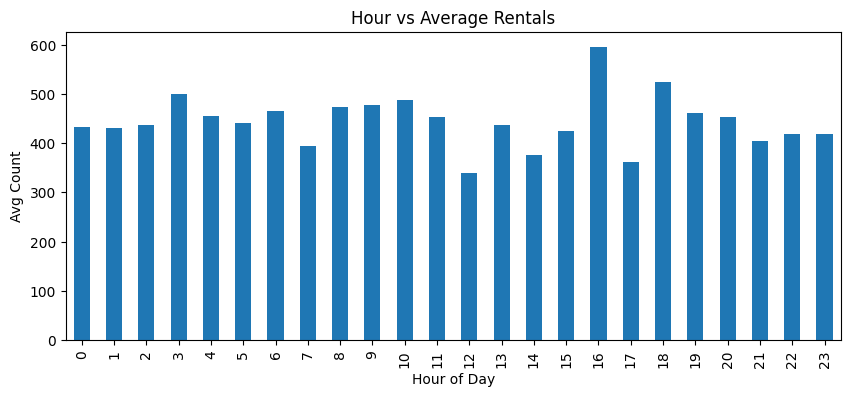

In [12]:
# Q42
hour_avg = df.groupby('Hour')['Count'].mean()
print(hour_avg)
plt.figure(figsize=(10,4))
hour_avg.plot(kind='bar')
plt.title("Hour vs Average Rentals")
plt.xlabel("Hour of Day")
plt.ylabel("Avg Count")
plt.show()
# Answer: Morning 8 AM aur Evening 5-6 PM pe peak hota hai - office time.

In [11]:
# Q43
import numpy as np
avg_temp = np.mean(df['Temp'])
avg_count = np.mean(df['Count'])
print("Average Temperature using NumPy:", round(avg_temp, 2))
print("Average Rental Count using NumPy:", round(avg_count, 2))

Average Temperature using NumPy: 20.13
Average Rental Count using NumPy: 444.76


In [10]:
# Q44
Q1 = df['Count'].quantile(0.25)
Q3 = df['Count'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5*IQR
outliers = df[df['Count'] > upper]
print("Q1:", Q1, "Q3:", Q3, "IQR:", IQR)
print("Upper Limit:", upper)
print("Unusually High Records:", len(outliers))
print(outliers[['DateTime','Count']].head())

Q1: 228.0 Q3: 645.25 IQR: 417.25
Upper Limit: 1271.125
Unusually High Records: 0
Empty DataFrame
Columns: [DateTime, Count]
Index: []


In [9]:
# Q45
summary = df.groupby(['Season','Weather'])['Count'].mean().reset_index()
print(summary)
# Answer: Har Season + Weather ka average nikal gaya. Ye table hi fleet planning ke kaam aayega.

    Season  Weather       Count
0        1        1  478.666667
1        1        2  471.676471
2        1        3  397.125000
3        1        4  672.500000
4        2        1  430.518987
5        2        2  457.121212
6        2        3  485.818182
7        2        4  312.285714
8        3        1  392.560000
9        3        2  393.448276
10       3        3  356.666667
11       3        4  415.666667
12       4        1  470.826087
13       4        2  483.184211
14       4        3  401.500000
15       4        4  533.600000


In [8]:
# Q46
df['DateTime'] = pd.to_datetime(df['DateTime'])
df['Date'] = df['DateTime'].dt.date
df['Hour'] = df['DateTime'].dt.hour

sorted_df = df.sort_values(by='Count', ascending=False)
print(sorted_df[['DateTime','Date','Hour','Count']].head(10))

               DateTime        Date  Hour  Count
328 2011-01-14 16:00:00  2011-01-14    16    899
325 2011-01-14 13:00:00  2011-01-14    13    899
2   2011-01-01 02:00:00  2011-01-01     2    893
499 2011-01-21 19:00:00  2011-01-21    19    892
133 2011-01-06 13:00:00  2011-01-06    13    888
138 2011-01-06 18:00:00  2011-01-06    18    886
7   2011-01-01 07:00:00  2011-01-01     7    885
343 2011-01-15 07:00:00  2011-01-15     7    884
464 2011-01-20 08:00:00  2011-01-20     8    884
347 2011-01-15 11:00:00  2011-01-15    11    883


In [6]:
# Q47
corr = df['Temp'].corr(df['Count'])
print("Correlation between Temp and Count:", round(corr, 3))
# Answer: Agar value positive hai to Temp badhne par Count bhi badhta hai.
# Humidity ka bhi check karo:
print("Humidity vs Count:", round(df['Humidity'].corr(df['Count']), 3))

Correlation between Temp and Count: 0.041
Humidity vs Count: 0.031


In [5]:
# Q48 - Sirf print karna hai, ye tumhara final answer hai
print("1. Peak hours (8 AM aur 5-6 PM) me zyada bikes rakho - office rush hai.")
print("2. Summer season me fleet badhao, Winter me kam rakho.")
print("3. Clear weather (Weather=1) me zyada bikes available rakho, Rain me kam.")
print("4. Weekdays par WorkingDay areas (office/colleges) me bikes zyada rakho.")
print("5. Temp zyada hone par demand badhti hai, isliye sunny days ke liye pehle se planning karo.")

1. Peak hours (8 AM aur 5-6 PM) me zyada bikes rakho - office rush hai.
2. Summer season me fleet badhao, Winter me kam rakho.
3. Clear weather (Weather=1) me zyada bikes available rakho, Rain me kam.
4. Weekdays par WorkingDay areas (office/colleges) me bikes zyada rakho.
5. Temp zyada hone par demand badhti hai, isliye sunny days ke liye pehle se planning karo.
